[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_00/MFM_ch0_bond_beta/MFM_ch0_bond_beta.ipynb)

# MFM_ch0_bond_beta

**Modelling Financial Markets (MFM) — Chapter 0: Financial Markets in 2026**

Treasury bond-stock betas after Pflueger (2025, Journal of Financial Economics): 10-year nominal Treasury excess returns regressed on US equity excess returns over 5-year rolling windows of quarters (1962-2026), and daily betas of 10-year nominal and inflation-indexed (TIPS) bonds on SPY over 120-day windows (2018-2026). Bond returns from FRED constant-maturity yields with a duration of 10 years.

Paper: Pflueger, C. (2025). [Back to the 1980s or not? The drivers of inflation and real risks in Treasury bonds](https://doi.org/10.1016/j.jfineco.2025.104027). *Journal of Financial Economics*, 167, 104027.

*Author: Daniel Traian Pele*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_0'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [2]:
import os
import io
import json
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

## Style and data loader

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'



In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
LOCAL_DIRS = ['../../../data/market', '../../data/market', '../data/market', 'data/market']   # cloned repository
START, END = '2000-01-01', '2026-09-18'

# name -> (source, symbol, field)
SERIES = {
    'SPY': ('market', 'SPY.US', 'adjusted_close'),
    'DGS10': ('fred', 'DGS10', None),            # 10-year Treasury, constant maturity (%)
    'DFII10': ('fred', 'DFII10', None),          # 10-year TIPS, constant maturity (%)
    'DTB3': ('fred', 'DTB3', None),              # 3-month T-bill, secondary market (%)
    'US market excess (FF)': ('french', 'F-F_Research_Data_Factors', 'Mkt-RF'),   # CRSP value-weighted, monthly
    'T-bill 1m (FF)': ('french', 'F-F_Research_Data_Factors', 'RF'),
}


def read_market(symbol):
    """Daily market series: local copy if the repository is cloned, otherwise GitHub."""
    for d in LOCAL_DIRS:
        path = os.path.join(d, f'{symbol}.csv')
        if os.path.exists(path):
            return pd.read_csv(path, index_col='date', parse_dates=True)
    return pd.read_csv(REPO_RAW + f'{symbol}.csv', index_col='date', parse_dates=True)


def fetch_daily(symbol, source='market', field='close', start=START, end=END):
    """Single access point to the data: returns a pd.Series (no NaN)."""
    if source == 'market':
        s = read_market(symbol)[field]
    elif source == 'fred':
        raw = urllib.request.urlopen(
            f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={symbol}', timeout=90).read().decode()
        s = pd.read_csv(io.StringIO(raw), index_col=0, parse_dates=True, na_values='.').iloc[:, 0]
    elif source == 'french':
        # Kenneth French Data Library (public zip): monthly Fama-French factors, in percent
        url = f'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/{symbol}_CSV.zip'
        raw = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}),
                                     timeout=120).read()
        z = zipfile.ZipFile(io.BytesIO(raw))
        lines = z.read(z.namelist()[0]).decode('latin-1').splitlines()
        i = next(k for k, l in enumerate(lines) if l.startswith(',') and len(l.split(',')) > 1)
        cols = [c.strip() for c in lines[i].split(',')[1:]]
        rows = {}
        for l in lines[i + 1:]:
            parts = [x.strip() for x in l.split(',')]
            if len(parts[0]) != 6 or not parts[0].isdigit():
                break                                                     # end of the monthly table
            rows[pd.Timestamp(parts[0] + '01') + pd.offsets.MonthEnd(0)] = float(parts[1 + cols.index(field)])
        s = pd.Series(rows) / 100.0                                       # percent -> decimal
    else:
        raise ValueError(f'unknown source: {source}')
    s = pd.to_numeric(s, errors='coerce')
    s.index = pd.to_datetime(s.index)
    s.index.name = 'Date'
    return s.sort_index().loc[start:end].dropna()


def load(name, start=START, end=END):
    """The series named in SERIES."""
    source, symbol, field = SERIES[name]
    return fetch_daily(symbol, source, field, start, end).rename(name)


## Data

Quarterly excess returns over the 3-month T-bill: the US market (CRSP value-weighted, from the Kenneth French library) and the 10-year Treasury, with r = -10 dy + y/4. Daily log returns: SPY and the 10-year nominal and TIPS bonds, with r = -10 dy + y/252.

In [5]:
DUR = 10.0                     # constant duration of the 10-year bond (years)
QWIN, DWIN = 20, 120           # 5-year rolling window (quarters), 120-trading-day window (days)
START_Q, END = '1962-01-01', '2026-09-18'
PANEL_B_START = '2018-01-01'
PAPER_PERIODS = [('1979Q4', '2001Q1'), ('2001Q2', '2019Q4'), ('2020Q1', None)]


def quarterly_excess():
    """Quarterly log excess returns over the 3-month T-bill: US market (CRSP VW) and the 10-year Treasury."""
    mkt = load('US market excess (FF)', START_Q, END) + load('T-bill 1m (FF)', START_Q, END)   # total return
    eq = np.log1p(mkt).resample('QE').agg(['sum', 'count'])
    eq = eq.loc[eq['count'] == 3, 'sum']                                  # complete quarters only
    y10 = load('DGS10', START_Q, END).resample('QE').last() / 100
    tb = load('DTB3', START_Q, END).resample('QE').last() / 100
    rf = tb.shift(1) / 4                                                  # T-bill yield known at the start
    bond = -DUR * y10.diff() + y10 / 4                                    # 10-year zero: -n dy + y/4
    df = pd.concat([eq - rf, bond - rf], axis=1, keys=['eq', 'bond']).dropna()
    df.index = df.index.to_period('Q')
    return df


def quarterly_tips():
    """Quarterly 10-year TIPS excess return (DFII10 starts in January 2003)."""
    y_r = load('DFII10', '2002-10-01', END).resample('QE').last() / 100
    tb = load('DTB3', '2002-10-01', END).resample('QE').last() / 100
    rq = (-DUR * y_r.diff() + y_r / 4 - tb.shift(1) / 4).dropna()
    rq.index = rq.index.to_period('Q')
    return rq


def daily_returns():
    """Daily log returns on common days: SPY (total return), 10-year nominal and TIPS bonds (duration 10)."""
    p = pd.concat([load('SPY', '1999-01-01', END), load('DGS10', '1999-01-01', END) / 100,
                   load('DFII10', '1999-01-01', END) / 100], axis=1)
    p.columns = ['spy', 'nom', 'tips']
    p = p.dropna(subset=['spy', 'nom'])                                   # common days of SPY and FRED
    out = pd.DataFrame({'eq': np.log(p['spy']).diff(),
                        'nom': -DUR * p['nom'].diff() + p['nom'] / 252,
                        'tips': -DUR * p['tips'].diff() + p['tips'] / 252})
    return out.iloc[1:]


def rolling_beta(y, x, w):
    """Rolling OLS slope of y on x over w observations."""
    return y.rolling(w).cov(x) / x.rolling(w).var()


def ols_beta(y, x):
    """OLS slope with heteroskedasticity-robust (HC1) standard error."""
    d = pd.concat([y, x], axis=1).dropna()
    yv, xv = d.iloc[:, 0].values, d.iloc[:, 1].values
    X = np.column_stack([np.ones_like(xv), xv])
    b = np.linalg.lstsq(X, yv, rcond=None)[0]
    e = yv - X @ b
    n = len(yv)
    XtXi = np.linalg.inv(X.T @ X)
    V = XtXi @ (X.T * e ** 2) @ X @ XtXi * n / (n - 2)
    return float(b[1]), float(np.sqrt(V[1, 1])), n


## Chart and results

In [6]:
def fig_pflueger_betas(save=True):
    q = quarterly_excess()
    bq = rolling_beta(q['bond'], q['eq'], QWIN).dropna()
    d = daily_returns()
    bn = rolling_beta(d['nom'], d['eq'], DWIN)
    dt = d.dropna(subset=['tips'])
    bt = rolling_beta(dt['tips'], dt['eq'], DWIN)
    bn_b, bt_b = bn.loc[PANEL_B_START:], bt.loc[PANEL_B_START:]

    fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.3), gridspec_kw={'width_ratios': [1.25, 1]})
    xq = bq.index.to_timestamp(how='end')
    axes[0].plot(xq, bq.values, color=MainBlue, lw=1.0, label='Nominal 10y Treasury beta')
    axes[0].axhline(0, color=Navy, lw=0.5)
    for dline in ['2001-04-01', '2020-01-01']:
        axes[0].axvline(pd.Timestamp(dline), color=Navy, lw=0.6, ls=':')
    axes[0].set_ylabel('Bond-stock beta')
    axes[0].set_title(f'A: quarterly, 5-year windows, {bq.index[0].year}-{bq.index[-1].year}', fontsize=8.5,
                      loc='left')
    axes[1].plot(bn_b.index, bn_b.values, color=MainBlue, lw=0.8)
    axes[1].plot(bt_b.index, bt_b.values, color=Amber, lw=0.8, label='Inflation-indexed 10y (TIPS) beta')
    axes[1].axhline(0, color=Navy, lw=0.5)
    axes[1].axvline(pd.Timestamp('2020-03-11'), color=Navy, lw=0.6, ls=':')
    axes[1].set_title('B: daily, 120-day windows, 2018-2026', fontsize=8.5, loc='left')
    axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.tight_layout()
    h0, l0 = axes[0].get_legend_handles_labels()
    h1, l1 = axes[1].get_legend_handles_labels()
    fig.legend(h0 + h1, l0 + l1, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=8)
    if save:
        for ext, kw in [('pdf', {}), ('png', {'dpi': 180})]:
            plt.savefig(os.path.join(OUT_DIR, f'ch0_pflueger_betas.{ext}'), bbox_inches='tight',
                        transparent=True, **kw)
    plt.show()
    plt.close()

    res = {'quarterly_sample': [str(q.index[0]), str(q.index[-1])], 'n_quarters': int(len(q)),
           'daily_sample': [str(d.index[0].date()), str(d.index[-1].date())], 'subperiods': {}}
    for a, b in PAPER_PERIODS:
        sub = q.loc[a:b] if b else q.loc[a:]
        beta, se, n = ols_beta(sub['bond'], sub['eq'])
        res['subperiods'][f'{a}-{b or str(q.index[-1])}'] = {'beta': round(beta, 3), 'se': round(se, 3), 'n': n}
    qt = pd.concat([quarterly_tips(), q['eq']], axis=1, keys=['tips', 'eq']).dropna()
    for a, b in [('2003Q2', '2019Q4'), ('2020Q1', None)]:
        sub = qt.loc[a:b] if b else qt.loc[a:]
        beta, se, n = ols_beta(sub['tips'], sub['eq'])
        res['subperiods'][f'TIPS {a}-{b or str(sub.index[-1])}'] = {'beta': round(beta, 3), 'se': round(se, 3),
                                                                     'n': n}
    pre, postq = bq.loc[:'2001Q1'], bq.loc['2001Q2':]
    res['q_roll'] = {'max_pre2001': [str(pre.idxmax()), round(float(pre.max()), 2)],
                     'min_post2001': [str(postq.idxmin()), round(float(postq.min()), 2)],
                     'last': [str(bq.index[-1]), round(float(bq.iloc[-1]), 2)],
                     'first_positive_after_2001': str(postq[postq > 0].index.min()),
                     'share_positive_pre2001': round(float((pre > 0).mean()), 3)}
    post = bn.loc['2020-03-11':].dropna()
    post_t = bt.loc['2020-03-11':].dropna()
    common = pd.concat([post, post_t], axis=1).dropna()
    res['d_roll'] = {'nom_last': [str(bn.index[-1].date()), round(float(bn.iloc[-1]), 2)],
                     'tips_last': [str(bt.index[-1].date()), round(float(bt.iloc[-1]), 2)],
                     'nom_max_post_covid': [str(post.idxmax().date()), round(float(post.max()), 2)],
                     'nom_share_positive_post_covid': round(float((post > 0).mean()), 3),
                     'nom_below_tips_share_post_covid':
                         round(float((common.iloc[:, 0] < common.iloc[:, 1]).mean()), 3)}
    res['d_year'] = {}
    for yr in range(2018, 2027):
        s = d.loc[str(yr)]
        bnom, senom, n = ols_beta(s['nom'], s['eq'])
        btip, setip, _ = ols_beta(s['tips'], s['eq'])
        bdif, sedif, _ = ols_beta(s['nom'] - s['tips'], s['eq'])       # nominal minus TIPS = -10 x d(breakeven)
        res['d_year'][str(yr)] = {'nom': round(bnom, 3), 'nom_se': round(senom, 3), 'tips': round(btip, 3),
                                  'tips_se': round(setip, 3), 'diff': round(bdif, 3), 'diff_se': round(sedif, 3),
                                  'n': n}
    with open(os.path.join(OUT_DIR, 'ch0_pflueger_results.json'), 'w') as f:
        json.dump(res, f, indent=1)
    return res, q, bq, d, bn, bt


## Run

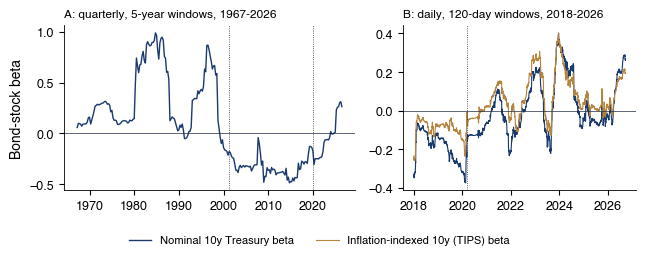

{
 "1979Q4-2001Q1": {
  "beta": 0.271,
  "se": 0.139,
  "n": 86
 },
 "2001Q2-2019Q4": {
  "beta": -0.344,
  "se": 0.064,
  "n": 75
 },
 "2020Q1-2026Q2": {
  "beta": -0.004,
  "se": 0.166,
  "n": 26
 },
 "TIPS 2003Q2-2019Q4": {
  "beta": -0.067,
  "se": 0.055,
  "n": 67
 },
 "TIPS 2020Q1-2026Q2": {
  "beta": 0.193,
  "se": 0.132,
  "n": 26
 }
}
{'max_pre2001': ['1984Q3', 0.99], 'min_post2001': ['2014Q3', -0.49], 'last': ['2026Q2', 0.26], 'first_positive_after_2001': '2023Q4', 'share_positive_pre2001': 0.905}
{'nom_last': ['2026-09-18', 0.27], 'tips_last': ['2026-09-18', 0.19], 'nom_max_post_covid': ['2023-12-19', 0.4], 'nom_share_positive_post_covid': 0.467, 'nom_below_tips_share_post_covid': 0.837}


In [7]:
res = fig_pflueger_betas()[0]
print(json.dumps(res['subperiods'], indent=1))
print(res['q_roll'])
print(res['d_roll'])

![ch0_pflueger_betas](./ch0_pflueger_betas.png)

Output: `ch0_pflueger_betas.pdf`, `ch0_pflueger_results.json`